<a href="https://colab.research.google.com/github/AngelikaBaloy/DS4002-Project2-Group5/blob/main/Airline_Project_EDA%26Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS4002 - Group 5 - Project 2: Data Cleaning & EDA

Group members: Angelika Baloy, Samuel Bromberg, Inmar Chavarria

## IAD Flight Departure Delay Rates

Packages

In [ ]:
#All Packages Needed
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

2024 Data

In [ ]:
#Data Merging & Cleaning for 2024

united = pd.read_csv("IAD_2024_United.csv", skiprows=7, usecols=range(17))
american = pd.read_csv("IAD_2024_American.csv", skiprows=7, usecols=range(17))
delta = pd.read_csv("IAD_2024_Delta.csv", skiprows=7, usecols=range(17))

#combine datasets
flights_2024 = pd.concat([united, american, delta], ignore_index=True)    #THIS IS THE NEW COMBINED DATASET

# Remove source information and empty rows
flights_2024 = flights_2024[
    flights_2024["Carrier Code"].isin(["UA", "AA", "DL"])
].copy()

# Convert date to datetime
flights_2024["Date (MM/DD/YYYY)"] = pd.to_datetime(flights_2024["Date (MM/DD/YYYY)"])

#check combined dataset
print(flights_2024.shape)
print(flights_2024["Carrier Code"].value_counts())


(36215, 17)
Carrier Code
UA    32249
DL     3225
AA      741
Name: count, dtype: int64


In [ ]:
#if you need to save the combined 2024 dataset, run this.
flights_2024.to_csv("IAD_2024_Combined.csv", index=False)

2025 Data

In [ ]:
#Data Merging & Cleaning for 2025

united = pd.read_csv("IAD_2025_United.csv", skiprows=7, usecols=range(17))
american = pd.read_csv("IAD_2025_American.csv", skiprows=7, usecols=range(17))
delta = pd.read_csv("IAD_2025_Delta.csv", skiprows=7, usecols=range(17))

#combine datasets
flights_2025 = pd.concat([united, american, delta], ignore_index=True)       #NEW COMBINED 2025 DATASET

#Remove source information and empty rows
flights_2025 = flights_2025[flights_2025["Carrier Code"].isin(["UA", "AA", "DL"])].copy()

# Convert date to datetime
flights_2025["Date (MM/DD/YYYY)"] = pd.to_datetime(flights_2025["Date (MM/DD/YYYY)"])

#check the combined dataset
print(flights_2025.shape)
print(flights_2025["Carrier Code"].value_counts())


(39140, 17)
Carrier Code
UA    35159
DL     2948
AA     1033
Name: count, dtype: int64


In [ ]:
#if you need to save the combined 2025 dataset, run this.
flights_2025.to_csv("IAD_2025_Combined.csv", index=False)

Exploratory Data Analysis

In [ ]:
flights_2024["Year"] = 2024
flights_2025["Year"] = 2025

# Combine datasets for EDA
flights = pd.concat([flights_2024, flights_2025], ignore_index=True)   #combines the two combined datasets (2024 and 2025)

# Convert variables
flights["Date (MM/DD/YYYY)"] = pd.to_datetime(flights["Date (MM/DD/YYYY)"])

flights["Departure delay (Minutes)"] = pd.to_numeric(flights["Departure delay (Minutes)"],errors="coerce")

flights = flights.dropna(subset=["Date (MM/DD/YYYY)", "Departure delay (Minutes)"]).copy()

# Create variables
flights["Delayed"] = (flights["Departure delay (Minutes)"] >= 15).astype(int)

flights["Month"] = flights["Date (MM/DD/YYYY)"].dt.month
flights["Quarter"] = flights["Date (MM/DD/YYYY)"].dt.quarter
flights["Day of Week"] = flights["Date (MM/DD/YYYY)"].dt.day_name()

# Airline colors
airline_colors = {"UA": "royalblue", "AA": "firebrick","DL": "forestgreen"}

airline_names = {"UA": "United","AA": "American","DL": "Delta"}

weekdays = ["Monday", "Tuesday", "Wednesday""Thursday", "Friday", "Saturday", "Sunday"]

sns.set_theme(style="whitegrid")



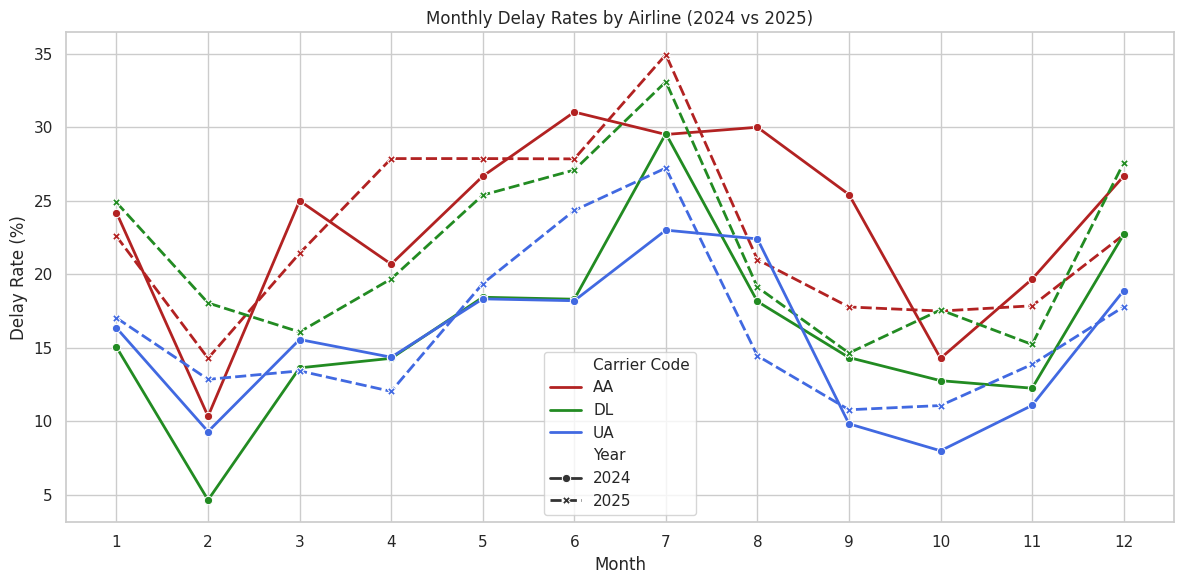

In [ ]:
monthly_airline = (
    flights.groupby(["Year", "Month", "Carrier Code"])["Delayed"]
    .mean()
    .mul(100)
    .reset_index(name="Delay Rate")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_airline,
    x="Month",
    y="Delay Rate",
    hue="Carrier Code",
    style="Year",
    palette=airline_colors,
    markers=True,
    dashes=True,
    linewidth=2
)

plt.title("Monthly Delay Rates by Airline (2024 vs 2025)")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()



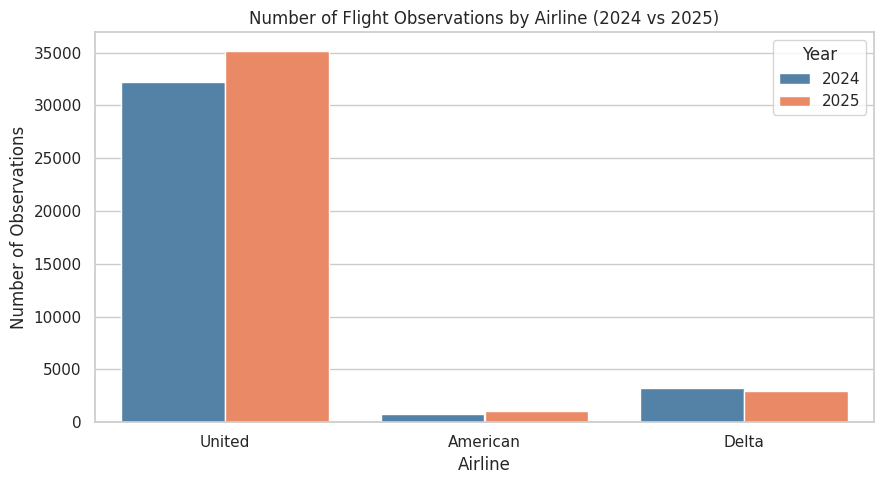

In [ ]:
# Bar graph
plt.figure(figsize=(9, 5))

sns.countplot(
    data=flights,
    x="Carrier Code",
    hue="Year",
    order=["UA", "AA", "DL"],
    palette=["steelblue", "coral"]
)

plt.title("Number of Flight Observations by Airline (2024 vs 2025)")
plt.xlabel("Airline")
plt.ylabel("Number of Observations")
plt.xticks([0, 1, 2], ["United", "American", "Delta"])
plt.legend(title="Year")
plt.tight_layout()
plt.show()
